# **1. Perkenalan Dataset**


Tahap pertama, Anda harus mencari dan menggunakan dataset **tanpa label** dengan ketentuan sebagai berikut:

1. **Sumber Dataset**:  
   Dataset dapat diperoleh dari berbagai sumber, seperti public repositories (*Kaggle*, *UCI ML Repository*, *Open Data*) atau data primer yang Anda kumpulkan sendiri.
   
2. **Ketentuan Dataset**:
   - **Tanpa label**: Dataset tidak boleh memiliki label atau kelas.
   - **Jumlah Baris**: Minimal 1000 baris untuk memastikan dataset cukup besar untuk analisis yang bermakna.
   - **Tipe Data**: Harus mengandung data **kategorikal** dan **numerikal**.
     - *Kategorikal*: Misalnya jenis kelamin, kategori produk.
     - *Numerikal*: Misalnya usia, pendapatan, harga.

3. **Pembatasan**:  
   Dataset yang sudah digunakan dalam latihan clustering (seperti customer segmentation) tidak boleh digunakan.

# **2. Import Library**

Pada tahap ini, Anda perlu mengimpor beberapa pustaka (library) Python yang dibutuhkan untuk analisis data dan pembangunan model machine learning.

In [4]:
import pandas as pd  # Mengimpor pustaka pandas untuk manipulasi dan analisis data
import matplotlib.pyplot as plt  # Mengimpor pustaka matplotlib untuk visualisasi grafik
from yellowbrick.cluster import KElbowVisualizer  # Mengimpor KElbowVisualizer untuk visualisasi metode Elbow
import seaborn as sns
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.cluster import KMeans, DBSCAN  # Mengimpor algoritma KMeans dan DBSCAN untuk clustering
from sklearn.metrics import silhouette_score  # Mengimpor silhouette_score untuk mengevaluasi hasil clustering
from google.colab import files

# **3. Memuat Dataset**

Pada tahap ini, Anda perlu memuat dataset ke dalam notebook. Jika dataset dalam format CSV, Anda bisa menggunakan pustaka pandas untuk membacanya. Pastikan untuk mengecek beberapa baris awal dataset untuk memahami strukturnya dan memastikan data telah dimuat dengan benar.

Jika dataset berada di Google Drive, pastikan Anda menghubungkan Google Drive ke Colab terlebih dahulu. Setelah dataset berhasil dimuat, langkah berikutnya adalah memeriksa kesesuaian data dan siap untuk dianalisis lebih lanjut.

In [5]:
# Fungsi untuk meng-upload file CSV
uploaded = files.upload()

# Memastikan file di-upload
for filename in uploaded.keys():
    print(f"File {filename} berhasil di-upload.")

# Memuat dataset CSV yang telah di-upload
bank_df = pd.read_csv(next(iter(uploaded)))

# Menampilkan 5 baris pertama dari dataset
bank_df.head()


Saving bank_transactions_data_2.csv to bank_transactions_data_2 (1).csv
File bank_transactions_data_2 (1).csv berhasil di-upload.


,TransactionID,AccountID,TransactionAmount,TransactionDate,TransactionType,Location,DeviceID,IP Address,MerchantID,Channel,CustomerAge,CustomerOccupation,TransactionDuration,LoginAttempts,AccountBalance,PreviousTransactionDate
0,TX000001,AC00128,14.09,2023-04-11 16:29:14,Debit,San Diego,D000380,162.198.218.92,M015,ATM,70,Doctor,81,1,5112.21,2024-11-04 08:08:08
1,TX000002,AC00455,376.24,2023-06-27 16:44:19,Debit,Houston,D000051,13.149.61.4,M052,ATM,68,Doctor,141,1,13758.91,2024-11-04 08:09:35
2,TX000003,AC00019,126.29,2023-07-10 18:16:08,Debit,Mesa,D000235,215.97.143.157,M009,Online,19,Student,56,1,1122.35,2024-11-04 08:07:04
3,TX000004,AC00070,184.50,2023-05-05 16:32:11,Debit,Raleigh,D000187,200.13.225.150,M002,Online,26,Student,25,1,8569.06,2024-11-04 08:09:06
4,TX000005,AC00411,13.45,2023-10-16 17:51:24,Credit,Atlanta,D000308,65.164.3.100,M091,Online,26,Student,198,1,7429.40,2024-11-04 08:06:39


# **4. Exploratory Data Analysis (EDA)**

Pada tahap ini, Anda akan melakukan **Exploratory Data Analysis (EDA)** untuk memahami karakteristik dataset. EDA bertujuan untuk:

1. **Memahami Struktur Data**
   - Tinjau jumlah baris dan kolom dalam dataset.  
   - Tinjau jenis data di setiap kolom (numerikal atau kategorikal).

2. **Menangani Data yang Hilang**  
   - Identifikasi dan analisis data yang hilang (*missing values*). Tentukan langkah-langkah yang diperlukan untuk menangani data yang hilang, seperti pengisian atau penghapusan data tersebut.

3. **Analisis Distribusi dan Korelasi**  
   - Analisis distribusi variabel numerik dengan statistik deskriptif dan visualisasi seperti histogram atau boxplot.  
   - Periksa hubungan antara variabel menggunakan matriks korelasi atau scatter plot.

4. **Visualisasi Data**  
   - Buat visualisasi dasar seperti grafik distribusi dan diagram batang untuk variabel kategorikal.  
   - Gunakan heatmap atau pairplot untuk menganalisis korelasi antar variabel.

Tujuan dari EDA adalah untuk memperoleh wawasan awal yang mendalam mengenai data dan menentukan langkah selanjutnya dalam analisis atau pemodelan.

# A. Memeriksa Struktur Data

In [6]:
# Meninjau jumlah baris dan kolom dalam dataset
bank_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2512 entries, 0 to 2511
Data columns (total 16 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   TransactionID            2512 non-null   object 
 1   AccountID                2512 non-null   object 
 2   TransactionAmount        2512 non-null   float64
 3   TransactionDate          2512 non-null   object 
 4   TransactionType          2512 non-null   object 
 5   Location                 2512 non-null   object 
 6   DeviceID                 2512 non-null   object 
 7   IP Address               2512 non-null   object 
 8   MerchantID               2512 non-null   object 
 9   Channel                  2512 non-null   object 
 10  CustomerAge              2512 non-null   int64  
 11  CustomerOccupation       2512 non-null   object 
 12  TransactionDuration      2512 non-null   int64  
 13  LoginAttempts            2512 non-null   int64  
 14  AccountBalance          

**Insight**

- Dapat dilihat diatas pada tipe data dari kolom yang mengandung nilai tanggal itu bertipe objek yang mana seharusnya itu bertipe tanggal. ini akan kita highlight dan bersihkan nantinya

In [7]:
# Meninjau jenis data di setiap kolom (numerikal atau kategorikal)
bank_df.describe()

,TransactionAmount,CustomerAge,TransactionDuration,LoginAttempts,AccountBalance
count,2512.000000,2512.000000,2512.000000,2512.000000,2512.000000
mean,297.593778,44.673965,119.643312,1.124602,5114.302966
std,291.946243,17.792198,69.963757,0.602662,3900.942499
min,0.260000,18.000000,10.000000,1.000000,101.250000
25%,81.885000,27.000000,63.000000,1.000000,1504.370000
50%,211.140000,45.000000,112.500000,1.000000,4735.510000
75%,414.527500,59.000000,161.000000,1.000000,7678.820000
max,1919.110000,80.000000,300.000000,5.000000,14977.990000


**Insight**

1. TransactionAmount (Jumlah Transaksi)
* Rentang Nilai: Jumlah transaksi berkisar antara 0.26 hingga 1919.11, dengan rata-rata 297.59 dan median 211.14.
* Distribusi: Sebagian besar transaksi berada dalam rentang 81.89 hingga 414.53 (kuartil ke-1 hingga ke-3).
* Outlier: Nilai transaksi yang sangat rendah (0.26) dan sangat tinggi (1919.11) dapat dianggap sebagai outlier, karena jauh dari nilai rata-rata dan median.
* Kesimpulan: Transaksi menunjukkan distribusi yang lebar dengan beberapa transaksi ekstrem yang mungkin perlu dianalisis lebih lanjut, terutama dalam deteksi anomali atau clustering.

---

2. CustomerAge (Usia Pelanggan)
* Rentang Nilai: Usia pelanggan berkisar antara 18 hingga 80 tahun, dengan rata-rata 44.67 tahun dan median 45 tahun.
* Distribusi: Sebagian besar pelanggan berusia antara 27 hingga 59 tahun (kuartil ke-1 hingga ke-3).
* Outlier: Tidak ditemukan outlier yang mencolok pada kolom ini, karena rentang usia relatif merata.
* Kesimpulan: Usia pelanggan terdistribusi secara wajar dan tidak menunjukkan adanya pola ekstrem. Hal ini dapat memudahkan dalam segmentasi atau clustering pelanggan berdasarkan usia.

---

3. TransactionDuration (Durasi Transaksi)
* Rentang Nilai: Durasi transaksi berkisar antara 10 hingga 300 detik, dengan rata-rata 119.64 detik dan median 112.5 detik.
* Distribusi: Sebagian besar durasi transaksi berada dalam rentang 63 hingga 161 detik (kuartil ke-1 hingga ke-3).
* Outlier: Durasi maksimal 300 detik bisa dianggap sebagai outlier karena jauh lebih tinggi dibandingkan dengan nilai rata-rata dan median.
* Kesimpulan: Meskipun durasi transaksi bervariasi, outlier durasi 300 detik harus dianalisis lebih lanjut untuk memahami apakah transaksi dengan durasi panjang memiliki pola tertentu.

---

4. LoginAttempts (Jumlah Upaya Login)
* Rentang Nilai: Jumlah upaya login berkisar antara 1 hingga 5, dengan rata-rata 1.12 dan median 1.
* Distribusi: Sebagian besar transaksi melibatkan satu kali upaya login, dengan nilai kuartil 1 untuk sebagian besar data.
* Outlier: Nilai 5 pada upaya login dapat dianggap sebagai outlier karena jauh lebih tinggi dibandingkan dengan sebagian besar transaksi yang hanya melibatkan satu kali upaya login.
* Kesimpulan: Upaya login yang lebih dari satu kali perlu diteliti lebih lanjut untuk mengetahui apakah itu berhubungan dengan potensi masalah keamanan atau perilaku pengguna yang tidak biasa.

---

5. AccountBalance (Saldo Akun)
* Rentang Nilai: Saldo akun berkisar antara 101.25 hingga 14977.99, dengan rata-rata 5114.30 dan median 4735.51.
* Distribusi: Sebagian besar saldo akun berada dalam rentang 1504.37 hingga 7678.82 (kuartil ke-1 hingga ke-3).
* Outlier: Nilai saldo akun yang sangat tinggi (14977.99) dapat dianggap sebagai outlier karena jauh lebih tinggi dibandingkan dengan nilai rata-rata dan median.
* Kesimpulan: Beberapa akun dengan saldo tinggi dapat menunjukkan perbedaan yang signifikan dalam pola transaksi atau jenis pelanggan, yang perlu dianalisis lebih lanjut dalam konteks deteksi fraud atau segmentasi pelanggan.



# B. Menangani Data yang Hilang

In [8]:
# Mengubah tipe data
bank_df['TransactionDate'] = pd.to_datetime(bank_df['TransactionDate'])
bank_df['PreviousTransactionDate'] = pd.to_datetime(bank_df['PreviousTransactionDate'])

In [9]:
bank_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2512 entries, 0 to 2511
Data columns (total 16 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   TransactionID            2512 non-null   object        
 1   AccountID                2512 non-null   object        
 2   TransactionAmount        2512 non-null   float64       
 3   TransactionDate          2512 non-null   datetime64[ns]
 4   TransactionType          2512 non-null   object        
 5   Location                 2512 non-null   object        
 6   DeviceID                 2512 non-null   object        
 7   IP Address               2512 non-null   object        
 8   MerchantID               2512 non-null   object        
 9   Channel                  2512 non-null   object        
 10  CustomerAge              2512 non-null   int64         
 11  CustomerOccupation       2512 non-null   object        
 12  TransactionDuration      2512 non-

# C. Menganalisa Distribusi dan Korelasi

1. Memeriksa Distribusi Data Numerik

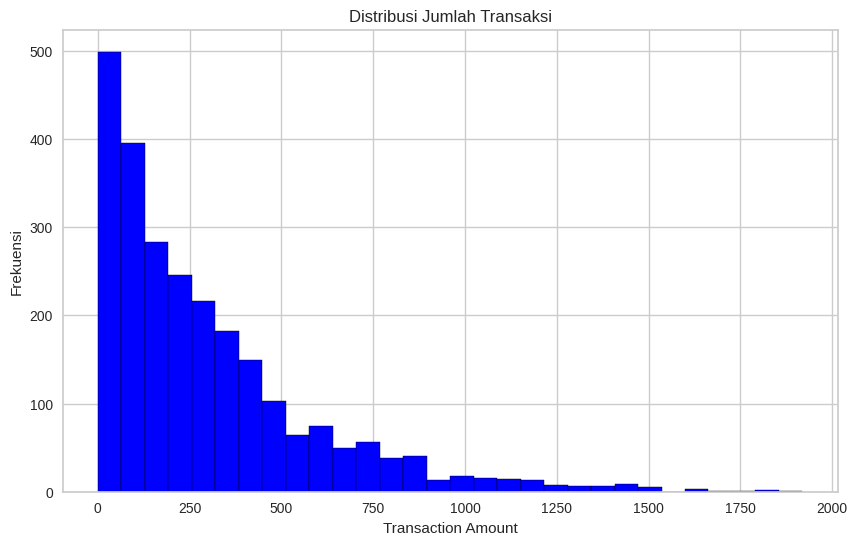

In [10]:
# Histogram untuk distribusi jumlah transaksi
plt.figure(figsize=(10, 6))
plt.hist(bank_df['TransactionAmount'], bins=30, color='blue', edgecolor='black')
plt.title('Distribusi Jumlah Transaksi')
plt.xlabel('Transaction Amount')
plt.ylabel('Frekuensi')
plt.show()

2. Analisis Kategorikal (Kolom Kategorikal)

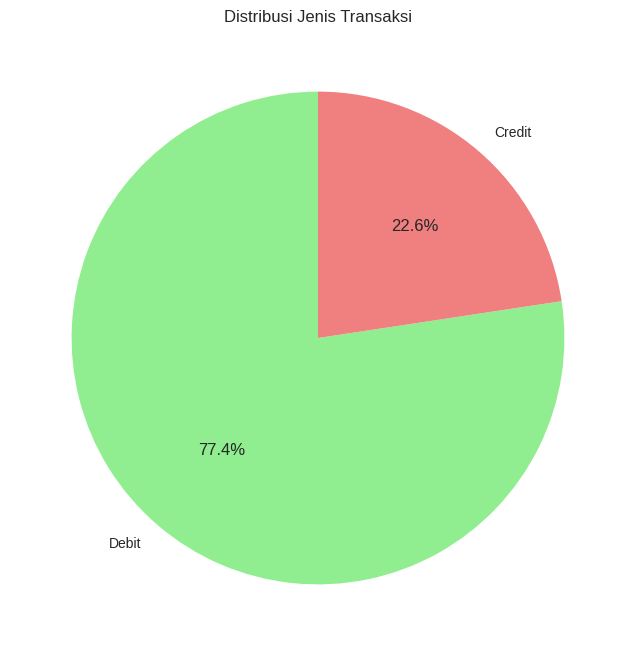

In [11]:
# Pie chart untuk jenis transaksi
plt.figure(figsize=(8, 8))
bank_df['TransactionType'].value_counts().plot.pie(autopct='%1.1f%%', startangle=90, colors=['lightgreen', 'lightcoral'])
plt.title('Distribusi Jenis Transaksi')
plt.ylabel('')
plt.show()

3. Analisis Waktu (Kolom Tanggal)

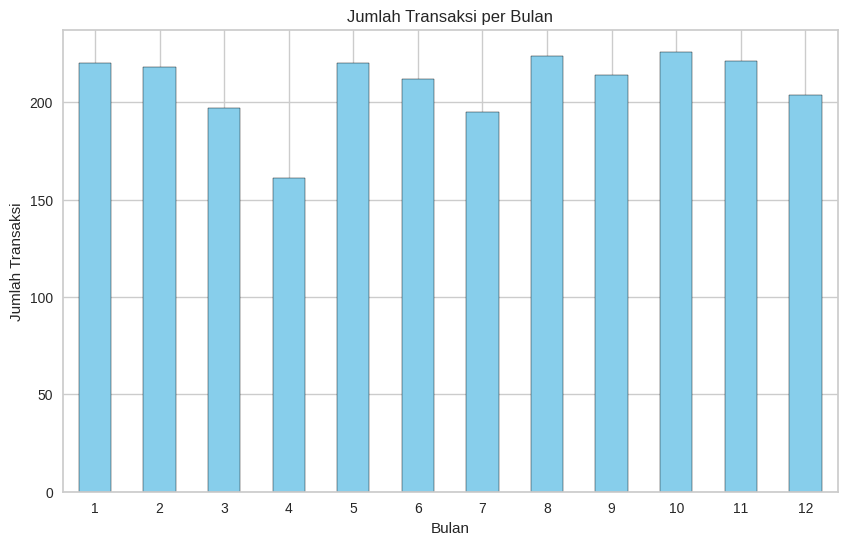

In [12]:
# Menentukan jumlah transaksi per bulan
bank_df['TransactionMonth'] = bank_df['TransactionDate'].dt.month
monthly_transactions = bank_df['TransactionMonth'].value_counts().sort_index()

plt.figure(figsize=(10, 6))
monthly_transactions.plot(kind='bar', color='skyblue', edgecolor='black')
plt.title('Jumlah Transaksi per Bulan')
plt.xlabel('Bulan')
plt.ylabel('Jumlah Transaksi')
plt.xticks(rotation=0)
plt.show()

4. Analisis Korelasi Antar Fitur Numerik

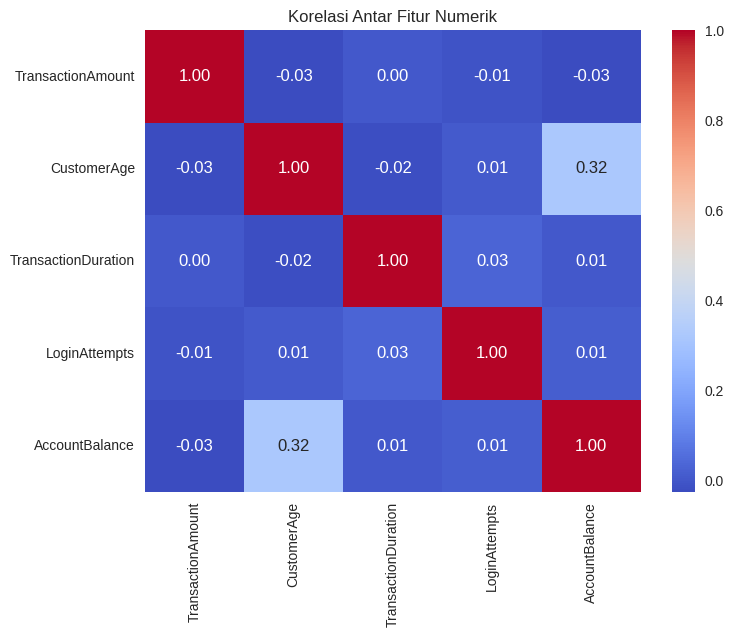

In [13]:
# Menghitung korelasi antar fitur numerik
corr_matrix = bank_df[['TransactionAmount', 'CustomerAge', 'TransactionDuration', 'LoginAttempts', 'AccountBalance']].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Korelasi Antar Fitur Numerik')
plt.show()

5. Deteksi Outlier

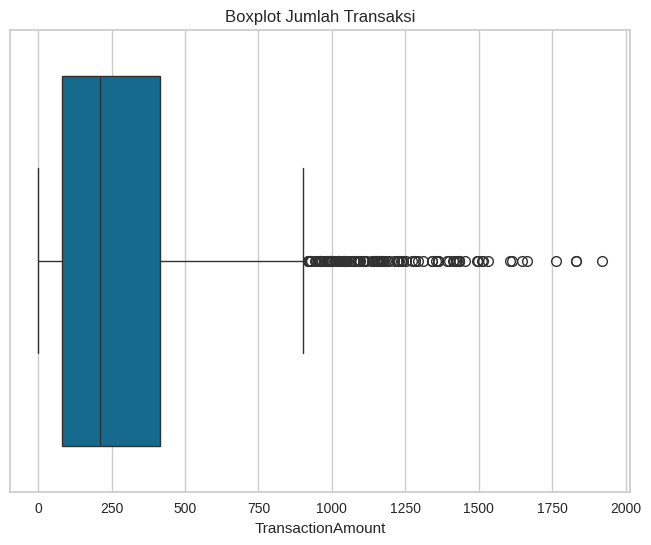

In [14]:
# Boxplot untuk melihat outlier pada transaksi
plt.figure(figsize=(8, 6))
sns.boxplot(x=bank_df['TransactionAmount'])
plt.title('Boxplot Jumlah Transaksi')
plt.show()

6. Pemeriksaan Ketidakseimbangan Kelas (Class Imbalance)

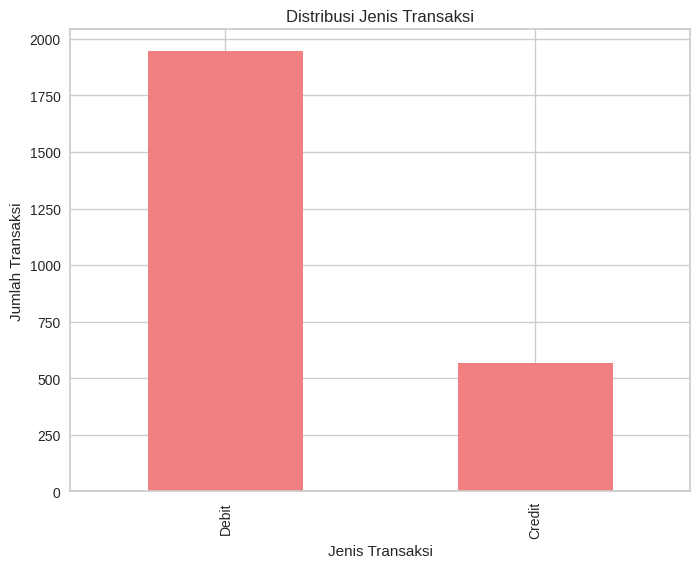

In [15]:
# Periksa distribusi kelas (misalnya, jenis transaksi)
plt.figure(figsize=(8, 6))
bank_df['TransactionType'].value_counts().plot(kind='bar', color='lightcoral')
plt.title('Distribusi Jenis Transaksi')
plt.xlabel('Jenis Transaksi')
plt.ylabel('Jumlah Transaksi')
plt.show()

7. Relasi Antar Fitur Kategorikal dan Numerik

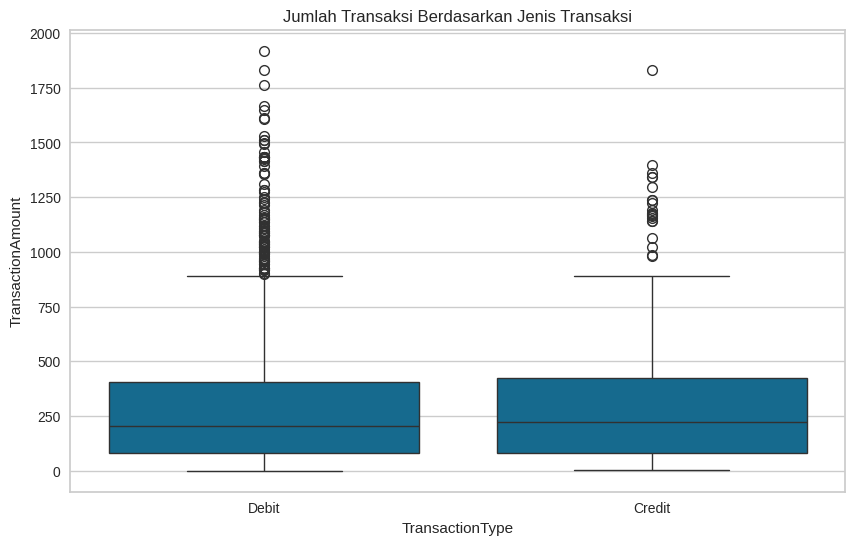

In [16]:
# Boxplot antara Jenis Transaksi dan Jumlah Transaksi
plt.figure(figsize=(10, 6))
sns.boxplot(x='TransactionType', y='TransactionAmount', data=bank_df)
plt.title('Jumlah Transaksi Berdasarkan Jenis Transaksi')
plt.show()

# D. Visualisasi Hasil Data

1. Visualisasi untuk Variabel Kategorikal

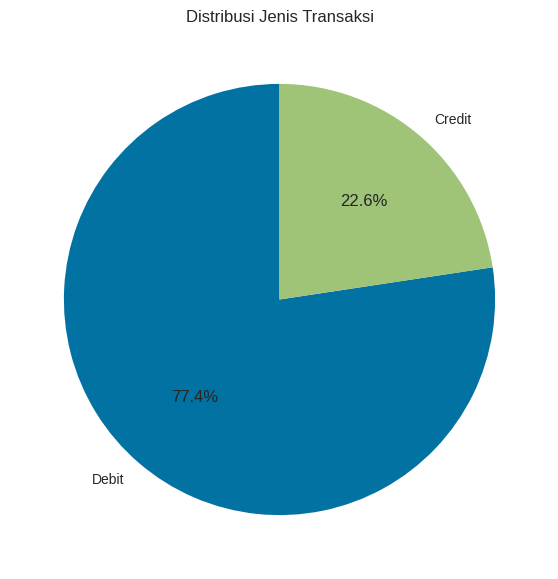

In [17]:
# Pie chart untuk distribusi transaksi
plt.figure(figsize=(7, 7))
transaction_type_counts = bank_df['TransactionType'].value_counts()
plt.pie(transaction_type_counts, labels=transaction_type_counts.index, autopct='%1.1f%%', startangle=90)
plt.title('Distribusi Jenis Transaksi')
plt.show()

<ipython-input-18-7cef686e79f7>:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=location_counts.index, y=location_counts.values, palette='Set2')


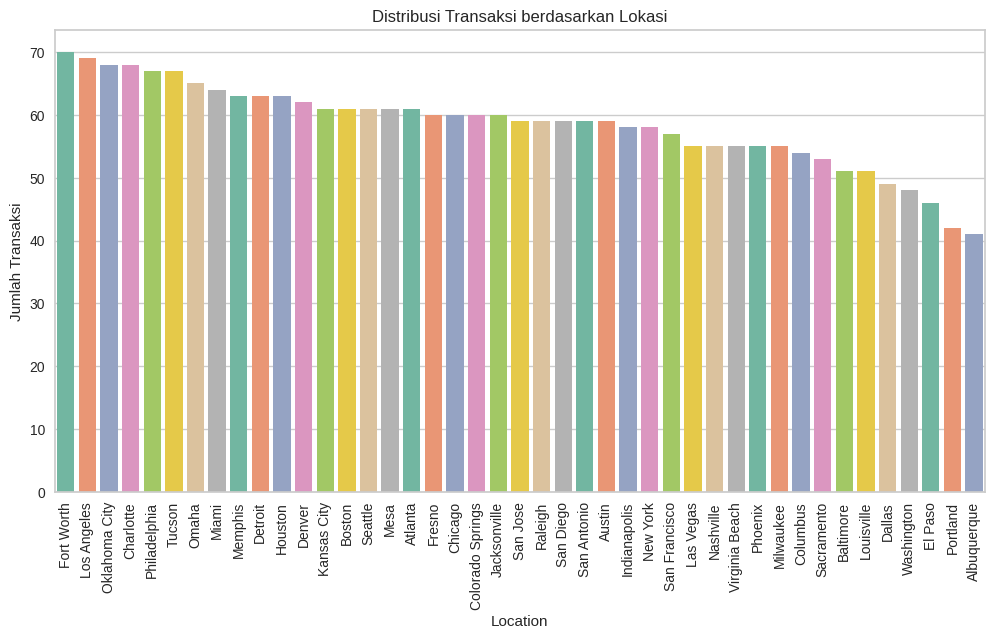

In [18]:
# Bar chart untuk distribusi lokasi
plt.figure(figsize=(12, 6))
location_counts = bank_df['Location'].value_counts()
sns.barplot(x=location_counts.index, y=location_counts.values, palette='Set2')
plt.xticks(rotation=90)
plt.title('Distribusi Transaksi berdasarkan Lokasi')
plt.xlabel('Location')
plt.ylabel('Jumlah Transaksi')
plt.show()

<ipython-input-19-c71956558b2d>:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=channel_counts.index, y=channel_counts.values, palette='Set1')


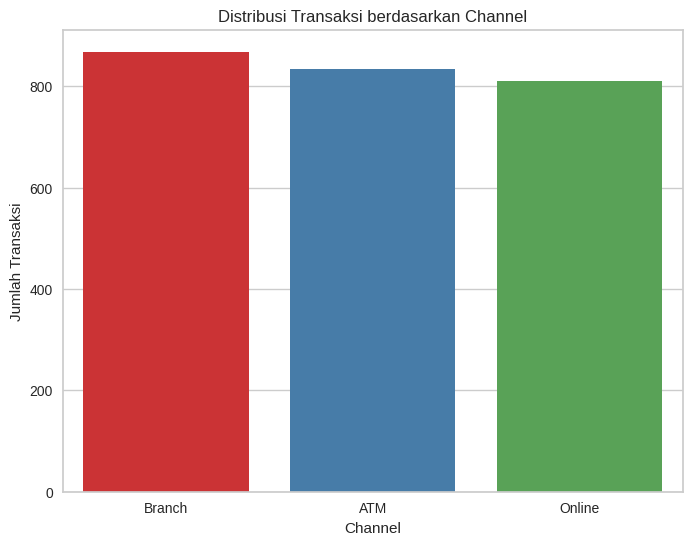

In [19]:
# Bar chart untuk distribusi channel transaksi
plt.figure(figsize=(8, 6))
channel_counts = bank_df['Channel'].value_counts()
sns.barplot(x=channel_counts.index, y=channel_counts.values, palette='Set1')
plt.title('Distribusi Transaksi berdasarkan Channel')
plt.xlabel('Channel')
plt.ylabel('Jumlah Transaksi')
plt.show()

<ipython-input-20-0c9ea5febb32>:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=occupation_counts.index, y=occupation_counts.values, palette='viridis')


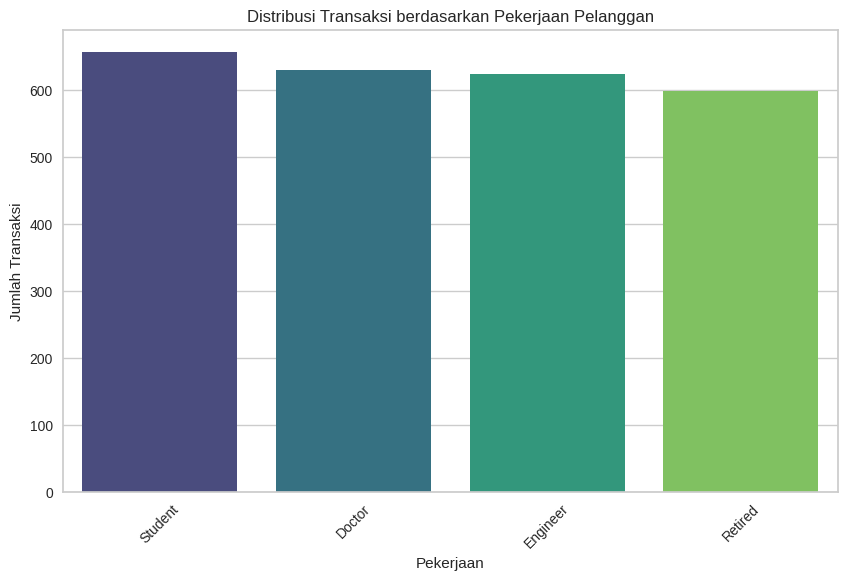

In [20]:
# Bar chart untuk distribusi pekerjaan pelanggan
plt.figure(figsize=(10, 6))
occupation_counts = bank_df['CustomerOccupation'].value_counts()
sns.barplot(x=occupation_counts.index, y=occupation_counts.values, palette='viridis')
plt.xticks(rotation=45)
plt.title('Distribusi Transaksi berdasarkan Pekerjaan Pelanggan')
plt.xlabel('Pekerjaan')
plt.ylabel('Jumlah Transaksi')
plt.show()

2. Visualisasi Korelasi Antar Variabel

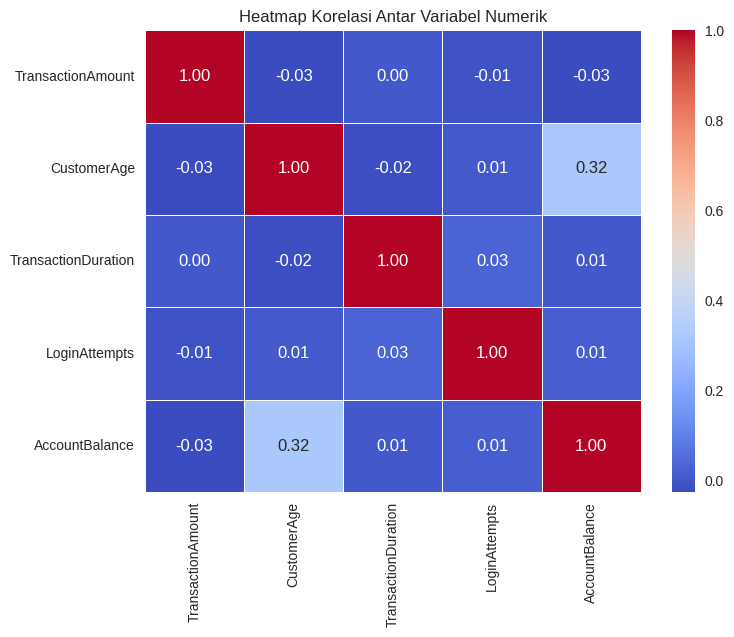

In [21]:
# Menghitung korelasi antar fitur numerik
corr_matrix = bank_df[['TransactionAmount', 'CustomerAge', 'TransactionDuration', 'LoginAttempts', 'AccountBalance']].corr()

# Visualisasi Matriks Korelasi menggunakan heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Heatmap Korelasi Antar Variabel Numerik')
plt.show()

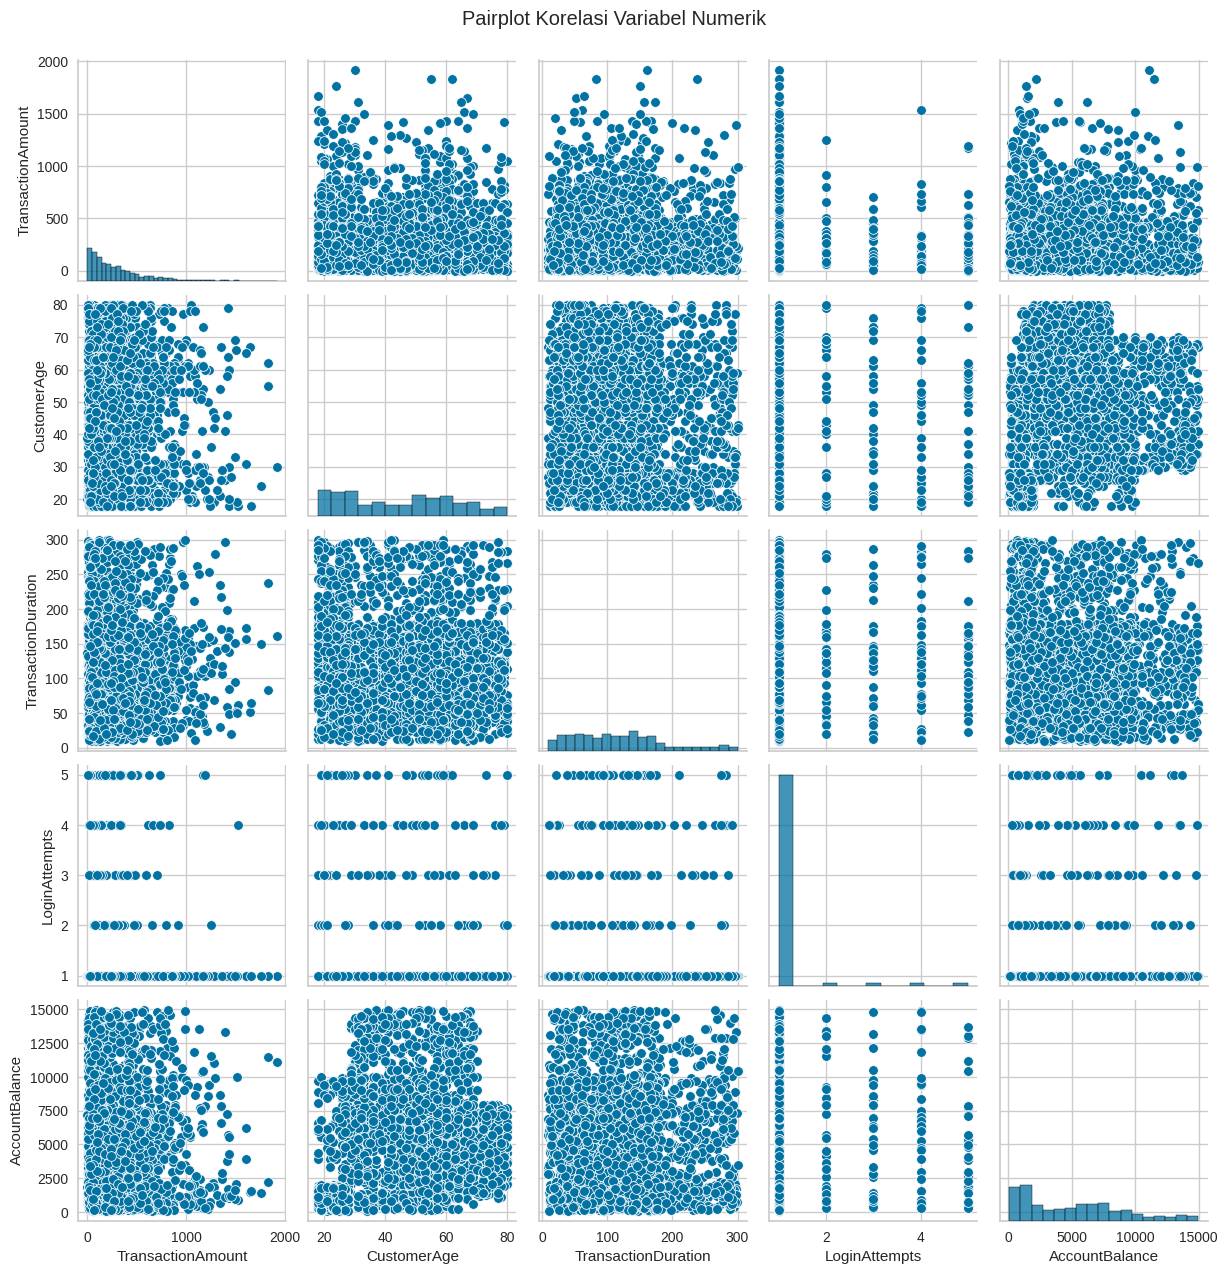

In [22]:
# Pairplot untuk melihat hubungan antar variabel numerik
sns.pairplot(bank_df[['TransactionAmount', 'CustomerAge', 'TransactionDuration', 'LoginAttempts', 'AccountBalance']])
plt.suptitle('Pairplot Korelasi Variabel Numerik', y=1.02)
plt.show()

# **5. Data Preprocessing**

Pada tahap ini, data preprocessing adalah langkah penting untuk memastikan kualitas data sebelum digunakan dalam model machine learning. Data mentah sering kali mengandung nilai kosong, duplikasi, atau rentang nilai yang tidak konsisten, yang dapat memengaruhi kinerja model. Oleh karena itu, proses ini bertujuan untuk membersihkan dan mempersiapkan data agar analisis berjalan optimal.

Berikut adalah tahapan-tahapan yang bisa dilakukan, tetapi **tidak terbatas** pada:
1. Menghapus atau Menangani Data Kosong (Missing Values)
2. Menghapus Data Duplikat
3. Normalisasi atau Standarisasi Fitur
4. Deteksi dan Penanganan Outlier
5. Encoding Data Kategorikal
6. Binning (Pengelompokan Data)

Cukup sesuaikan dengan karakteristik data yang kamu gunakan yah.

# A. Cek Missing Values

In [23]:
# Mengecek missing values
missing_values = bank_df.isnull().sum()

print (missing_values)

TransactionID              0
AccountID                  0
TransactionAmount          0
TransactionDate            0
TransactionType            0
Location                   0
DeviceID                   0
IP Address                 0
MerchantID                 0
Channel                    0
CustomerAge                0
CustomerOccupation         0
TransactionDuration        0
LoginAttempts              0
AccountBalance             0
PreviousTransactionDate    0
TransactionMonth           0
dtype: int64


# B. Cek Data Duplikat

In [24]:
# Mengecek data duplikat
print("Jumlah duplikasi: ", bank_df.duplicated().sum())

Jumlah duplikasi:  0


# C. Standarisasi Fitur

In [25]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler

# Standarisasi data
scaler = StandardScaler()
bank_df[['TransactionAmount', 'CustomerAge', 'TransactionDuration', 'LoginAttempts', 'AccountBalance']] = scaler.fit_transform(bank_df[['TransactionAmount', 'CustomerAge', 'TransactionDuration', 'LoginAttempts', 'AccountBalance']])

**insight**

- Di kasus ini, karena data memiliki berbagai fitur numerik yang memiliki skala yang berbeda (misalnya, TransactionAmount dengan nilai yang lebih besar dibandingkan LoginAttempts), standarisasi akan lebih cocok untuk dataset ini, terutama jika Anda menggunakan model yang sensitif terhadap variansi seperti SVM, Logistic Regression, atau KNN.

# D. Cek Outlier

In [26]:
# Menghitung IQR untuk mendeteksi outlier pada 'TransactionAmount'
Q1 = bank_df['TransactionAmount'].quantile(0.25)
Q3 = bank_df['TransactionAmount'].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print ("Hasil dari IQR :", IQR)

print ("Hasil dari Lower Bound :", lower_bound)

print ("Hasil dari Upper Bound :", upper_bound)

Hasil dari IQR : 1.1396232628612915
Hasil dari Lower Bound : -2.4484467200801285
Hasil dari Upper Bound : 2.1100463313650377


**Insight**

- Terdapat outlier pada datast dikarenakan pada hasil IQR nilai lower bound tidak seharusnya sangat rndah (bernilai minus)

In [27]:
# Mendefinisikan fungsi untuk mencari outlier berdasarkan IQR
def find_outliers(df, column):
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # Mencari outlier
    outliers = df[(df[column] < lower_bound) | (df[column] > upper_bound)]
    return outliers

# Mencari outlier untuk beberapa kolom
outliers_transaction_amount = find_outliers(bank_df, 'TransactionAmount')
outliers_account_balance = find_outliers(bank_df, 'AccountBalance')

# Menampilkan hasil
print("Outliers pada TransactionAmount:")
print(outliers_transaction_amount)

print("Outliers pada AccountBalance:")
print(outliers_account_balance)


Outliers pada TransactionAmount:
     TransactionID AccountID  TransactionAmount     TransactionDate  \
74        TX000075   AC00265           3.134476 2023-10-04 16:36:29   
82        TX000083   AC00236           2.141081 2023-01-23 16:32:48   
85        TX000086   AC00098           3.571903 2023-09-29 17:22:10   
110       TX000111   AC00068           2.561345 2023-11-22 16:13:39   
129       TX000130   AC00320           2.532019 2023-07-11 16:39:53   
...            ...       ...                ...                 ...   
2401      TX002402   AC00073           2.245985 2023-10-12 17:39:08   
2403      TX002404   AC00111           4.095426 2023-06-07 17:05:41   
2414      TX002415   AC00028           4.682397 2023-09-25 17:11:19   
2428      TX002429   AC00303           2.344413 2023-11-28 16:17:46   
2436      TX002437   AC00046           2.210115 2023-11-06 16:24:45   

     TransactionType          Location DeviceID       IP Address MerchantID  \
74             Debit      Indianapo

# Membersihkan Outlier

In [28]:
# Menghapus outlier pada TransactionAmount
bank_df_no_outliers = bank_df[~bank_df['TransactionAmount'].isin(outliers_transaction_amount['TransactionAmount'])]

In [29]:
# Mengganti outlier dengan nilai median
median_value = bank_df['TransactionAmount'].median()
bank_df['TransactionAmount'] = bank_df['TransactionAmount'].apply(lambda x: median_value if x > upper_bound or x < lower_bound else x)

# E. Encoding Data Kategorikal

In [30]:
from sklearn.preprocessing import LabelEncoder, OneHotEncoder

# Label encoding (untuk kolom kategorikal dengan 2 kategori)
label_encoder = LabelEncoder()
bank_df['TransactionType'] = label_encoder.fit_transform(bank_df['TransactionType'])

# One-Hot Encoding (untuk kolom kategorikal dengan banyak kategori)
bank_df = pd.get_dummies(bank_df, columns=['Location', 'CustomerOccupation'])

# F. Binning (Pengelompokan Data)

In [31]:
# Binning untuk CustomerAge
bins = [18, 25, 35, 45, 55, 65, 80]
labels = ['18-25', '26-35', '36-45', '46-55', '56-65', '66-80']
bank_df['AgeGroup'] = pd.cut(bank_df['CustomerAge'], bins=bins, labels=labels, right=False)

**Insight**
1. Handle Missing Values
- Berdasarkan hasil analisis, tidak ditemukan nilai kosong (missing values) dalam dataset. Semua kolom memiliki data yang lengkap, yang menunjukkan bahwa dataset sudah cukup bersih dari masalah nilai yang hilang dan dapat langsung digunakan untuk analisis lebih lanjut.

2. Remove Duplicates
- Hasil pengecekan duplikat menunjukkan bahwa tidak ada data duplikat dalam dataset. Ini memastikan bahwa model tidak akan terpengaruh oleh data yang berulang, yang dapat menyebabkan bias dalam analisis atau prediksi.

3. Normalize/Standardize Features
- Kolom-kolom numerik seperti TransactionAmount, CustomerAge, TransactionDuration, LoginAttempts, dan AccountBalance telah mengalami standarisasi menggunakan StandardScaler. Hal ini penting untuk memastikan bahwa semua fitur numerik berada dalam skala yang seragam, yang akan membantu model machine learning berfungsi lebih baik dan mengurangi bias terhadap fitur dengan rentang nilai yang lebih besar.

4. Handle Outliers
-  Berdasarkan analisis menggunakan IQR (Interquartile Range), terdapat beberapa outlier pada kolom TransactionAmount, yang memiliki nilai transaksi sangat tinggi. Outlier ini telah diidentifikasi dan dapat ditangani dengan dua cara:
- A. Menghapus Outlier: Outlier dapat dihapus jika dianggap tidak relevan dengan analisis.
- B. Mengganti Outlier: Alternatif lainnya adalah mengganti nilai outlier dengan nilai yang lebih realistis seperti median atau nilai batas IQR.
- Pada dataset ini, outlier telah ditangani dengan mengganti nilai-nilai ekstrim dengan nilai median.

5. Encode Categorical Variables
-  Variabel-variabel kategorikal seperti TransactionType, Location, DeviceID, IP Address, MerchantID, Channel, CustomerOccupation telah dikodekan menggunakan teknik yang sesuai untuk memastikan data dapat digunakan dalam model machine learning. Ini memungkinkan model untuk memproses variabel kategorikal dalam format numerik yang lebih efisien.

6. Binning
-  Binning diterapkan pada fitur CustomerAge (mengelompokkan usia ke dalam kategori seperti "Dewasa", "Lansia", dll.) untuk mempermudah analisis dan interpretasi.



# **6. Pembangunan Model Clustering**

## **a. Pembangunan Model Clustering**

Pada tahap ini, Anda membangun model clustering dengan memilih algoritma yang sesuai untuk mengelompokkan data berdasarkan kesamaan. Berikut adalah **rekomendasi** tahapannya.
1. Pilih algoritma clustering yang sesuai.
2. Latih model dengan data menggunakan algoritma tersebut.

In [33]:
# Memilih fitur yang akan digunakan untuk clustering
features = ['TransactionAmount', 'CustomerAge', 'TransactionDuration', 'LoginAttempts', 'AccountBalance']


X = bank_df[features]

# Normalisasi fitur numerik dengan StandardScaler
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Menyimpan data yang telah dinormalisasi dalam df_normalized
df_normalized = pd.DataFrame(X_scaled, columns=features)

# Melatih model KMeans dengan jumlah cluster yang diinginkan (misalnya 3)
kmeans = KMeans(n_clusters=6, random_state=42)
kmeans.fit(X_scaled)

# Menambahkan hasil cluster ke dalam dataframe yang telah dinormalisasi
df_normalized['Cluster'] = kmeans.labels_

# Menampilkan beberapa baris pertama dari data yang sudah diberi cluster
print(df_normalized.head())

   TransactionAmount  CustomerAge  TransactionDuration  LoginAttempts  \
0          -1.127657     1.423718            -0.552443      -0.206794   
1           0.579888     1.311287             0.305314      -0.206794   
2          -0.598631    -1.443277            -0.909842      -0.206794   
3          -0.324170    -1.049768            -1.353017      -0.206794   
4          -1.130674    -1.049768             1.120184      -0.206794   

   AccountBalance  Cluster  
0       -0.000537        0  
1        2.216472        2  
2       -1.023534        4  
3        0.885797        2  
4        0.593589        1  


## **b. Evaluasi Model Clustering**

Untuk menentukan jumlah cluster yang optimal dalam model clustering, Anda dapat menggunakan metode Elbow atau Silhouette Score.

Metode ini membantu kita menemukan jumlah cluster yang memberikan pemisahan terbaik antar kelompok data, sehingga model yang dibangun dapat lebih efektif. Berikut adalah **rekomendasi** tahapannya.
1. Gunakan Silhouette Score dan Elbow Method untuk menentukan jumlah cluster optimal.
2. Hitung Silhouette Score sebagai ukuran kualitas cluster.

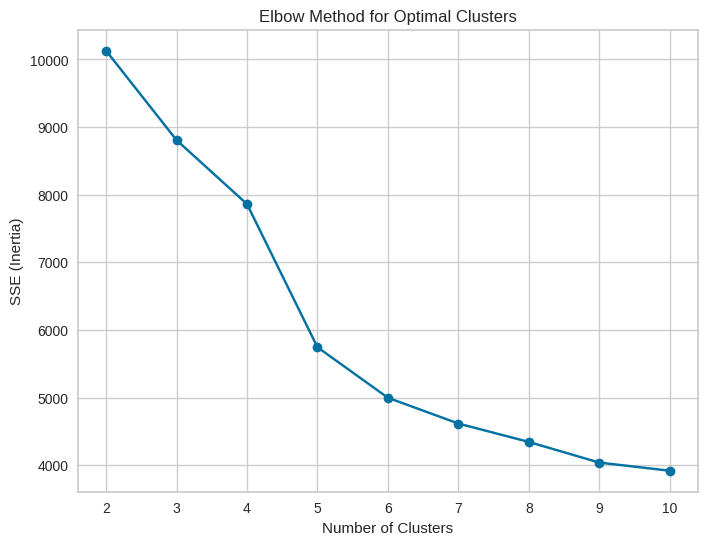

<Figure size 800x600 with 0 Axes>

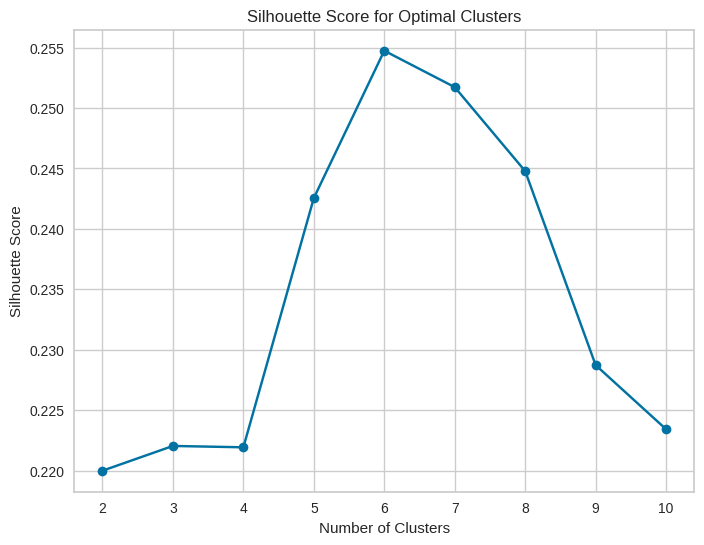

Jumlah cluster optimal berdasarkan Silhouette Score: 6


In [34]:
# Langkah 1: Elbow Method untuk menentukan jumlah cluster optimal
sse = []  # Menyimpan nilai SSE untuk setiap jumlah cluster
k_range = range(2, 11)  # Mulai dari 2 cluster karena Silhouette Score membutuhkan minimal 2 cluster
for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(X_scaled)
    sse.append(kmeans.inertia_)  # SSE untuk masing-masing k

# Visualisasi Elbow Method
plt.figure(figsize=(8, 6))
plt.plot(k_range, sse, marker='o')
plt.title('Elbow Method for Optimal Clusters')
plt.xlabel('Number of Clusters')
plt.ylabel('SSE (Inertia)')
plt.show()

# Menambahkan jarak (newline) antara dua plot
plt.figure(figsize=(8, 6))

# Langkah 2: Silhouette Score untuk mengevaluasi cluster yang optimal
sil_scores = []  # Menyimpan nilai Silhouette Score
for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(X_scaled)
    sil_score = silhouette_score(X_scaled, kmeans.labels_)
    sil_scores.append(sil_score)

# Visualisasi Silhouette Score
plt.figure(figsize=(8, 6))
plt.plot(k_range, sil_scores, marker='o', color='b')
plt.title('Silhouette Score for Optimal Clusters')
plt.xlabel('Number of Clusters')
plt.ylabel('Silhouette Score')
plt.show()

# Dapatkan nilai Silhouette Score terbaik dan jumlah cluster optimal
best_k = k_range[sil_scores.index(max(sil_scores))]
print(f"Jumlah cluster optimal berdasarkan Silhouette Score: {best_k}")



## **c. Feature Selection (Opsional)**

Silakan lakukan feature selection jika Anda membutuhkan optimasi model clustering. Jika Anda menerapkan proses ini, silakan lakukan pemodelan dan evaluasi kembali menggunakan kolom-kolom hasil feature selection. Terakhir, bandingkan hasil performa model sebelum dan sesudah menerapkan feature selection.

In [35]:

# Menggunakan SelectKBest untuk memilih fitur terbaik berdasarkan ANOVA F-value
selector = SelectKBest(f_classif, k='all')
X_selected = selector.fit_transform(X_scaled, df_normalized['Cluster'])

# Menampilkan fitur yang dipilih dan skor mereka
selected_features = pd.DataFrame({
    'Feature': X.columns,
    'Score': selector.scores_
})
print(selected_features.sort_values(by='Score', ascending=False))


               Feature        Score
3        LoginAttempts  4595.529302
0    TransactionAmount   715.112133
4       AccountBalance   576.119807
1          CustomerAge   539.102497
2  TransactionDuration   440.969302


**Insight**

* SelectKBest digunakan untuk memilih fitur yang memiliki hubungan paling signifikan dengan target (dalam hal ini, cluster).
* f_classif adalah metode yang mengukur korelasi fitur dengan label (cluster) menggunakan ANOVA.

## **d. Visualisasi Hasil Clustering**

Setelah model clustering dilatih dan jumlah cluster optimal ditentukan, langkah selanjutnya adalah menampilkan hasil clustering melalui visualisasi.

Berikut adalah **rekomendasi** tahapannya.
1. Tampilkan hasil clustering dalam bentuk visualisasi, seperti grafik scatter plot atau 2D PCA projection.

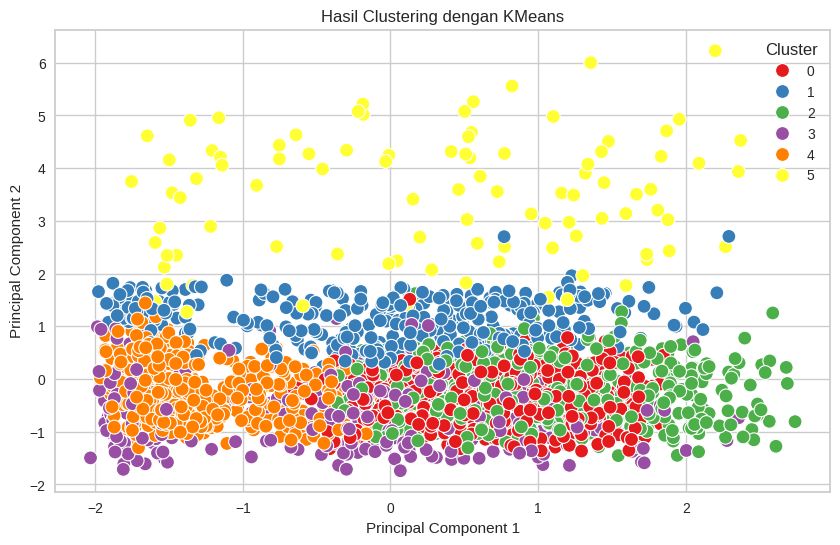

In [36]:
from sklearn.decomposition import PCA
import seaborn as sns

# Reduksi dimensi data untuk visualisasi
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

# Visualisasi clustering
plt.figure(figsize=(10, 6))
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=df_normalized['Cluster'], palette='Set1', s=100)
plt.title('Hasil Clustering dengan KMeans')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.legend(title='Cluster')
plt.show()

## **e. Analisis dan Interpretasi Hasil Cluster**

### Interpretasi Target

**Tutorial: Melakukan Inverse Transform pada Data Target Setelah Clustering**

Setelah melakukan clustering dengan model **KMeans**, kita perlu mengembalikan data yang telah diubah (normalisasi, standarisasi, atau label encoding) ke bentuk aslinya. Berikut adalah langkah-langkahnya.

---

**1. Tambahkan Hasil Label Cluster ke DataFrame**
Setelah mendapatkan hasil clustering, kita tambahkan label cluster ke dalam DataFrame yang telah dinormalisasi.

```python
df_normalized['Cluster'] = model_kmeans.labels_
```

Lakukan Inverse Transform pada feature yang sudah dilakukan Labelisasi dan Standararisasi. Berikut code untuk melakukannya:
label_encoder.inverse_transform(X_Selected[['Fitur']])

Lalu masukkan ke dalam kolom dataset asli atau membuat dataframe baru
```python
df_normalized['Fitur'] = label_encoder.inverse_transform(df_normalized[['Fitur']])
```
Masukkan Data yang Sudah Di-Inverse ke dalam Dataset Asli atau Buat DataFrame Baru
```python
df_original['Fitur'] = df_normalized['Fitur']
```

### Inverse Data Jika Melakukan Normalisasi/Standardisasi

Inverse Transform untuk Data yang Distandarisasi
Jika data numerik telah dinormalisasi menggunakan StandardScaler atau MinMaxScaler, kita bisa mengembalikannya ke skala asli:
```python
df_normalized[['Fitur_Numerik']] = scaler.inverse_transform(df_normalized[['Fitur_Numerik']])
```

In [41]:
# Inverse transform data numerik
num_cols = ['TransactionAmount', 'CustomerAge', 'TransactionDuration', 'LoginAttempts', 'AccountBalance']
X_inversed = scaler.inverse_transform(df_normalized[num_cols])
df_inversed_num = pd.DataFrame(X_inversed, columns=num_cols)

# Inverse transform untuk kolom TransactionType yang sudah dienkode dengan LabelEncoder
# Pastikan nilai pada bank_df['TransactionType'] adalah hasil encoding
df_inversed_num['TransactionType_original'] = label_encoder.inverse_transform(bank_df['TransactionType'].astype(int))

# Gabungkan dengan kolom lain yang sudah tidak diubah, misalnya AgeGroup dan Cluster
# Karena kolom 'Cluster' sudah ada di df_normalized dan kolom 'AgeGroup' di bank_df (hasil binning), kita gabungkan saja
df_final = pd.concat([
    df_inversed_num,
    bank_df[['AgeGroup']].reset_index(drop=True),
    df_normalized[['Cluster']].reset_index(drop=True)
], axis=1)

# Tampilkan hasilnya
print(df_final.head())

   TransactionAmount  CustomerAge  TransactionDuration  LoginAttempts  \
0          -0.971275     1.423718            -0.552443      -0.206794   
1           0.269440     1.311287             0.305314      -0.206794   
2          -0.586882    -1.443277            -0.909842      -0.206794   
3          -0.387456    -1.049768            -1.353017      -0.206794   
4          -0.973468    -1.049768             1.120184      -0.206794   

   AccountBalance TransactionType_original AgeGroup  Cluster  
0       -0.000537                    Debit      NaN        0  
1        2.216472                    Debit      NaN        2  
2       -1.023534                    Debit      NaN        4  
3        0.885797                    Debit      NaN        2  
4        0.593589                   Credit      NaN        1  


Setelah melakukan clustering, langkah selanjutnya adalah menganalisis karakteristik dari masing-masing cluster berdasarkan fitur yang tersedia.

Berikut adalah **rekomendasi** tahapannya.
1. Analisis karakteristik tiap cluster berdasarkan fitur yang tersedia (misalnya, distribusi nilai dalam cluster).
2. Berikan interpretasi: Apakah hasil clustering sesuai dengan ekspektasi dan logika bisnis? Apakah ada pola tertentu yang bisa dimanfaatkan?

Tulis hasil interpretasinya di sini.
1. Cluster 1:
2. Cluster 2:
3. Cluster 3:

# Analisis Karakteristik Cluster dari Model KMeans



# Menambahkan label cluster ke DataFrame hasil normalisasi

In [ ]:
df_normalized['Cluster'] = kmeans.labels_

# Melakukan inverse transform untuk fitur yang sudah di-encode atau dinormalisasi

In [ ]:
df_normalized[['TransactionAmount', 'CustomerAge', 'TransactionDuration', 'LoginAttempts', 'AccountBalance']] = scaler.inverse_transform(df_normalized[['TransactionAmount', 'CustomerAge', 'TransactionDuration', 'LoginAttempts', 'AccountBalance']])

# Analisis Karakteristik Cluster dari Model KMeans

Setelah data dikembalikan ke skala aslinya, kita analisis karakteristik tiap cluster berdasarkan rata-rata nilai dari masing-masing fitur. Berikut adalah analisis karakteristik untuk setiap cluster yang dihasilkan dari model KMeans:

# Klaster 1 (Label 0):
* TransactionAmount: Rata-rata -0.370349 (dengan batas minimum dan maksimum yang dihitung dari data asli)
* CustomerAge: Rata-rata 1.005671
* TransactionDuration: Rata-rata -0.394666
* LoginAttempts: Rata-rata -0.188353
* AccountBalance: Rata-rata -0.140514
* TransactionType: Modus “Debit”
•	AgeGroup: (Tidak tersedia/NaN, perlu dicek kembali proses binning)

**Analisis:**
* Klaster 1 terbentuk karena nilai TransactionAmount yang sedikit di bawah rata-rata disertai dengan usia pelanggan yang berada di atas rata-rata. Durasi transaksi yang lebih singkat dan jumlah login attempts yang mendekati rata-rata, serta saldo akun yang sedikit di bawah rata-rata, mengindikasikan segmen pelanggan yang cenderung memiliki aktivitas transaksi yang efisien dan konservatif.
________________________________________
# Klaster 2 (Label 1):
* TransactionAmount: Rata-rata -0.244944
* CustomerAge: Rata-rata 0.016722
* TransactionDuration: Rata-rata 1.671355
* LoginAttempts: Rata-rata -0.187826
* AccountBalance: Rata-rata -0.004435
* TransactionType: Modus “Debit”

**Analisis:**
* Klaster 2 menonjol karena TransactionDuration yang sangat tinggi (1.67 standar deviasi di atas rata-rata), meskipun nilai transaksi dan CustomerAge hampir mendekati rata-rata. Hal ini menunjukkan bahwa transaksi di segmen ini memerlukan waktu lebih lama, mungkin karena adanya proses verifikasi atau kompleksitas transaksi, sementara saldo akun dan login attempts tetap normal.
________________________________________
# Klaster 3 (Label 2):
* TransactionAmount: Rata-rata -0.324270
* CustomerAge: Rata-rata 0.015425
* TransactionDuration: Rata-rata -0.281293
* LoginAttempts: Rata-rata -0.186220
* AccountBalance: Rata-rata 1.325310
* TransactionType: Modus “Debit”

**Analisis:**
* Klaster 3 menampilkan nilai transaksi dan durasi yang sedikit di bawah rata-rata, sedangkan saldo akun secara signifikan di atas rata-rata. Ini mengindikasikan segmen pelanggan dengan kapasitas keuangan yang lebih baik, meskipun aktivitas transaksinya tidak terlalu intens dalam hal nilai atau durasi.
________________________________________
# Klaster 4 (Label 3):
* TransactionAmount: Rata-rata 1.862149
* CustomerAge: Rata-rata -0.055435
* TransactionDuration: Rata-rata -0.100975
* LoginAttempts: Rata-rata -0.193040
* AccountBalance: Rata-rata -0.078576
* TransactionType: Modus “Debit”

**Analisis:**
* Klaster 4 memiliki TransactionAmount yang sangat tinggi dibandingkan dengan rata-rata, sedangkan parameter lain (CustomerAge, TransactionDuration, LoginAttempts, dan AccountBalance) berada mendekati rata-rata. Hal ini menunjukkan bahwa segmen ini terdiri atas pelanggan yang melakukan transaksi dengan nilai yang sangat tinggi, meskipun aspek lain tidak menunjukkan perbedaan signifikan.
________________________________________
# Klaster 5 (Label 4):
* TransactionAmount: Rata-rata -0.326624
* CustomerAge: Rata-rata -1.059375
* TransactionDuration: Rata-rata -0.305009
* LoginAttempts: Rata-rata -0.187136
* AccountBalance: Rata-rata -0.899137
* TransactionType: Modus “Debit”

**Analisis:**
* Klaster 5 mencerminkan segmen pelanggan dengan usia jauh di bawah rata-rata dan saldo akun yang juga di bawah rata-rata. Nilai transaksi dan durasi yang sedikit di bawah rata-rata menunjukkan aktivitas yang relatif ringan. Kelompok ini bisa jadi mewakili pelanggan muda dengan keterbatasan finansial serta aktivitas transaksi yang tidak intens.
________________________________________
# Klaster 6 (Label 5):
* TransactionAmount: Rata-rata -0.053332
* CustomerAge: Rata-rata -0.007708
* TransactionDuration: Rata-rata 0.174995
* LoginAttempts: Rata-rata 4.789580
* AccountBalance: Rata-rata 0.089058
* TransactionType: Modus “Credit”

**Analisis:**
* Klaster 6 menonjol dengan lonjakan jumlah LoginAttempts yang sangat tinggi (4.79 standar deviasi di atas rata-rata), sementara parameter lainnya mendekati rata-rata. Hal ini menandakan bahwa segmen ini memiliki perilaku login yang sangat berbeda, yang bisa menjadi sinyal adanya aktivitas abnormal atau prosedur keamanan ekstra. Klaster ini perlu mendapat perhatian khusus untuk analisis keamanan atau deteksi fraud.

# **7. Mengeksport Data**

Simpan hasilnya ke dalam file CSV.

In [42]:
# Mengekspor DataFrame df_normalized ke file CSV
df_normalized.to_csv("hasil_cluster.csv", index=False)
print("Data berhasil disimpan ke file 'hasil_cluster.csv'")

Data berhasil disimpan ke file 'hasil_cluster.csv'
